# 04. Testing the GMM Like a Real Bank (Evaluation & Thresholds)
**Project 26:** Card Fraud Triage  
**Team ID:** T047 (Section A)
**Lead:** Naveen Kumar  

---
### What is this notebook about? (In Simple Words)
Up until now, our GMM gives each transaction an **anomaly score** (a number like 15.2 or 78.4).

A continuous number doesn't stop fraud. A bank needs a clear decision:
> **"Should we ring the alarm and block the card? YES or NO?"**

To turn our score into a YES/NO decision, we need to pick an **Alarm Threshold** (a cutoff line $\tau$):
* If Anomaly Score $\ge \tau \implies$ **Ring Alarm! (Fraud detected)**
* If Anomaly Score $< \tau \implies$ **Safe. (Approve transaction)**

### Two Real-World Bank Scenarios:
1. **Scenario A (Strict False Alarm Budget):**  
   The bank says: *"We only want at most 0.5% false alarms so we don't annoy innocent customers."*  
   How much fraud do we catch under this strict budget?
2. **Scenario B (Human Review Capacity):**  
   The fraud team says: *"We only have enough staff to investigate 50 alerts per shift."*  
   If we hand them the top 50 most suspicious transactions, how many are real fraudsters?

### The Golden Rule:
We choose the cutoff threshold on the **Validation Set**.  
Then we test it **once** on the **Test Set** (which the model has never seen before!).

### Step 1: Import basic libraries

In [1]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_auc_score, auc, confusion_matrix, average_precision_score

print("Libraries imported successfully!")

Libraries imported successfully!


### Step 2: Load our trained model and data
We load:
- Our saved champion GMM model from Milestone 3
- The scaler and the feature list chosen in notebook 03
- The Validation and Test datasets

In [2]:
# Load model, scaler, and features
model_dir = '../results/models'
if not os.path.exists(model_dir):
    model_dir = 'results/models'

model = joblib.load(os.path.join(model_dir, 'gmm_champion.joblib'))
scaler = joblib.load(os.path.join(model_dir, 'gmm_scaler.joblib'))
features = joblib.load(os.path.join(model_dir, 'gmm_features.joblib'))

# Load validation and test data
val_path = '../data/processed/val_mixed.csv'
test_path = '../data/processed/test_mixed.csv'
if not os.path.exists(val_path):
    val_path = 'data/processed/val_mixed.csv'
    test_path = 'data/processed/test_mixed.csv'

val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("Champion GMM model loaded successfully!")
print("Features used:", features)
print(f"Validation rows: {len(val_df):,} (Frauds: {(val_df['Class'] == 1).sum()})")
print(f"Test rows:       {len(test_df):,} (Frauds: {(test_df['Class'] == 1).sum()})")

Champion GMM model loaded successfully!
Features used: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
Validation rows: 56,745 (Frauds: 57)
Test rows:       56,746 (Frauds: 74)


### Step 3: Compute Anomaly Scores on the Validation Set
The GMM calculates how weird each transaction looks:
`anomaly_score = -model.score_samples(X)`
- High score = Highly weird / abnormal
- Low score = Looks just like a normal customer

In [3]:
# Prepare validation features
X_val = val_df[features].copy()
X_val['Amount'] = np.log1p(X_val['Amount'])
X_val_s = scaler.transform(X_val)

y_val = val_df['Class'].values

# Calculate anomaly score (negative log-likelihood)
val_scores = -model.score_samples(X_val_s)

print("Validation scores calculated!")
print(f"Lowest score (very normal):   {val_scores.min():.2f}")
print(f"Highest score (super weird):  {val_scores.max():.2f}")

Validation scores calculated!
Lowest score (very normal):   -14.23
Highest score (super weird):  787170.05


### Step 4: Pick the Alarm Cutoff (Threshold) on Validation Set
Let's find the threshold for **Bank Scenario A**:
- The bank says: *"Tolerate at most 0.5% false alarms on normal customers."*
- We take the 99.5th percentile of normal customer scores on the validation set!

In [4]:
# Get scores of honest transactions in validation
normal_val_scores = val_scores[y_val == 0]

# 0.5% false alarm rate means 99.5% of honest transactions are approved safely
target_fpr = 0.005
chosen_threshold = np.percentile(normal_val_scores, 100 * (1 - target_fpr))

print(f"Chosen Alarm Threshold: {chosen_threshold:.2f}")
print(f"Any transaction with score >= {chosen_threshold:.2f} will trigger an alert!")

Chosen Alarm Threshold: 94.68
Any transaction with score >= 94.68 will trigger an alert!


### Step 5: Unlock the Test Set! (The Final Exam)
Now we apply our model to the **Test Set** (which has been frozen and untouched).

We calculate:
1. **Test Average Precision (AP):** main ranking metric (area under the PR curve, step-wise).
2. **Test PR-AUC (trapezoidal):** shown for comparison with the first version; it can overstate the area.
3. **Test ROC-AUC:** supplementary metric.
4. **Random Baseline:** the test fraud rate.

In [5]:
# Prepare test features
X_test = test_df[features].copy()
X_test['Amount'] = np.log1p(X_test['Amount'])
X_test_s = scaler.transform(X_test)

y_test = test_df['Class'].values

# Calculate test anomaly scores
test_scores = -model.score_samples(X_test_s)

# Ranking metrics
prec_test, rec_test, _ = precision_recall_curve(y_test, test_scores)
test_ap = average_precision_score(y_test, test_scores)
test_pr_auc = auc(rec_test, prec_test)
test_roc_auc = roc_auc_score(y_test, test_scores)

fraud_rate_test = y_test.mean()

print("=== FINAL TEST SET RESULTS ===")
print(f"Random Guess Baseline:      {fraud_rate_test:.4f} ({fraud_rate_test*100:.2f}%)")
print(f"GMM Test AP:                {test_ap:.4f}  ({test_ap / fraud_rate_test:.0f}x the random baseline)")
print(f"GMM Test PR-AUC (trapz):    {test_pr_auc:.4f}")
print(f"GMM Test ROC-AUC:           {test_roc_auc:.4f}")

=== FINAL TEST SET RESULTS ===
Random Guess Baseline:      0.0013 (0.13%)
GMM Test AP:                0.6121  (469x the random baseline)
GMM Test PR-AUC (trapz):    0.6083
GMM Test ROC-AUC:           0.9229


### Step 6: Test Confusion Matrix at 0.5% False Alarm Budget
Now we apply our frozen validation threshold to the test set:
- How many real frauds did we catch? (True Positives / Recall)
- How many honest customers were annoyed? (False Positives)

In [6]:
# Predict: 1 if score >= threshold, else 0
test_preds = (test_scores >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()

print("=== TEST PERFORMANCE AT 0.5% FALSE ALARM BUDGET ===")
print(f"True Frauds Caught (TP):      {tp} out of {tp + fn} ({tp / (tp + fn) * 100:.1f}% Recall)")
print(f"Frauds Missed (FN):           {fn} out of {tp + fn}")
print(f"False Alarms (FP):            {fp} out of {tn + fp} normal purchases ({fp / (tn + fp) * 100:.2f}% False Positive Rate)")
print(f"Honest Purchases Safe (TN):   {tn:,}")

=== TEST PERFORMANCE AT 0.5% FALSE ALARM BUDGET ===
True Frauds Caught (TP):      56 out of 74 (75.7% Recall)
Frauds Missed (FN):           18 out of 74
False Alarms (FP):            158 out of 56672 normal purchases (0.28% False Positive Rate)
Honest Purchases Safe (TN):   56,514


### Step 7: Bank Scenario B — Top 25, 50, and 100 Review Capacity
If human investigators can only inspect a few alerts per shift, how accurate are our top alerts?

In [7]:
print("=== HUMAN REVIEW CAPACITY METRICS ===")
for k in [25, 50, 100]:
    # Get top k highest anomaly scores
    top_indices = np.argsort(test_scores)[::-1][:k]
    frauds_caught = y_test[top_indices].sum()
    precision_k = (frauds_caught / k) * 100
    print(f"Top {k:<3} Alerts -> {frauds_caught} are REAL FRAUD! (Precision = {precision_k:.1f}%)")

=== HUMAN REVIEW CAPACITY METRICS ===
Top 25  Alerts -> 18 are REAL FRAUD! (Precision = 72.0%)
Top 50  Alerts -> 42 are REAL FRAUD! (Precision = 84.0%)
Top 100 Alerts -> 56 are REAL FRAUD! (Precision = 56.0%)


### Step 8: Plot the Test Precision-Recall Curve

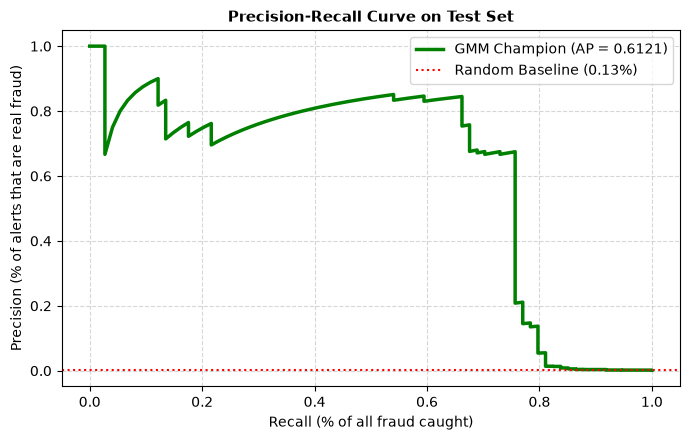

In [8]:
fig_dir = '../results/figures'
if not os.path.exists(fig_dir):
    fig_dir = 'results/figures'

plt.figure(figsize=(7, 4.5))
plt.plot(rec_test, prec_test, color='green', linewidth=2.5, label=f'GMM Champion (AP = {test_ap:.4f})')
plt.axhline(y=fraud_rate_test, color='red', linestyle=':', label=f'Random Baseline ({fraud_rate_test*100:.2f}%)')

plt.title("Precision-Recall Curve on Test Set", fontsize=11, fontweight='bold')
plt.xlabel("Recall (% of all fraud caught)", fontsize=10)
plt.ylabel("Precision (% of alerts that are real fraud)", fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'fig6_gmm_test_pr_curve.png'))
plt.show()

### Step 9: Plot the Confusion Matrix

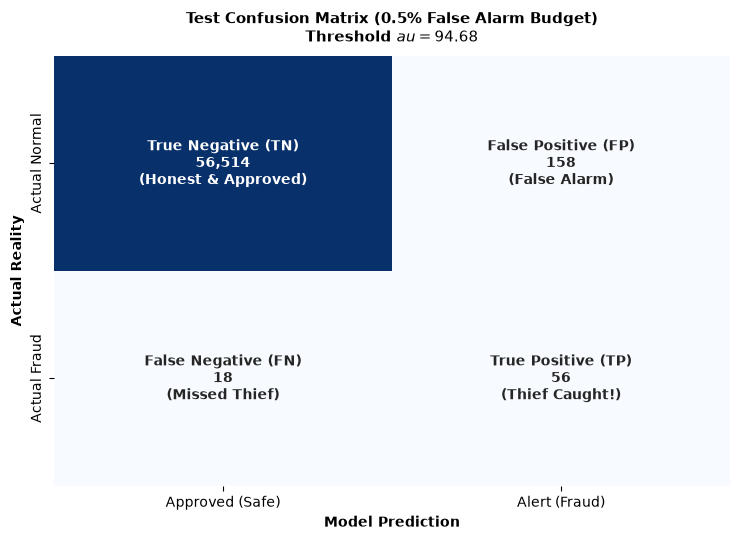

In [9]:
fig_dir = '../results/figures'
if not os.path.exists(fig_dir):
    fig_dir = 'results/figures'
os.makedirs(fig_dir, exist_ok=True)

annot_matrix = np.array([
    [f'True Negative (TN)\n{tn:,}\n(Honest & Approved)', f'False Positive (FP)\n{fp:,}\n(False Alarm)'],
    [f'False Negative (FN)\n{fn:,}\n(Missed Thief)',     f'True Positive (TP)\n{tp:,}\n(Thief Caught!)']
])  

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=False,
            annot_kws={'fontsize': 10, 'fontweight': 'bold'},
            xticklabels=['Approved (Safe)', 'Alert (Fraud)'],
            yticklabels=['Actual Normal', 'Actual Fraud'])

plt.title('Test Confusion Matrix (0.5% False Alarm Budget)\nThreshold $\tau = 94.68$', fontsize=11, fontweight='bold', pad=10)
plt.ylabel('Actual Reality', fontsize=10, fontweight='bold')
plt.xlabel('Model Prediction', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'fig7_gmm_test_confusion_matrix.png'), dpi=300)
plt.show()

### Step 10: Bootstrap 95% Confidence Intervals
The test set has only 74 frauds, so every metric is noisy. We resample the test set with replacement 1,000 times (keeping the threshold fixed) and report the 2.5th–97.5th percentile of each metric.

In [10]:
rng = np.random.default_rng(42)
n_boot = 1000
boot = {'AP': [], 'ROC_AUC': [], 'recall_at_threshold': [], 'precision_top_50': []}

for _ in range(n_boot):
    idx = rng.integers(0, len(y_test), len(y_test))
    y_b, s_b = y_test[idx], test_scores[idx]
    if y_b.sum() == 0:
        continue
    boot['AP'].append(average_precision_score(y_b, s_b))
    boot['ROC_AUC'].append(roc_auc_score(y_b, s_b))
    boot['recall_at_threshold'].append(((s_b >= chosen_threshold) & (y_b == 1)).sum() / y_b.sum())
    boot['precision_top_50'].append(y_b[np.argsort(s_b)[::-1][:50]].mean())

point = {'AP': test_ap, 'ROC_AUC': test_roc_auc,
         'recall_at_threshold': tp / (tp + fn),
         'precision_top_50': y_test[np.argsort(test_scores)[::-1][:50]].mean()}
ci = {m: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for m, v in boot.items()}

print("=== TEST METRICS WITH 95% BOOTSTRAP CI ===")
for m in boot:
    print(f"{m:<22} {point[m]:.3f}   [{ci[m][0]:.3f}, {ci[m][1]:.3f}]")

=== TEST METRICS WITH 95% BOOTSTRAP CI ===
AP                     0.612   [0.485, 0.743]
ROC_AUC                0.923   [0.879, 0.962]
recall_at_threshold    0.757   [0.658, 0.847]
precision_top_50       0.840   [0.700, 0.940]


### Step 11: Save Final Test Metrics to Disk

In [11]:
metrics_dir = '../results/metrics'
if not os.path.exists(metrics_dir):
    metrics_dir = 'results/metrics'
os.makedirs(metrics_dir, exist_ok=True)

test_metrics = {
    'model': f'GMM (K={model.n_components}, Full Covariance, {len(features)} Features)',
    'features': list(features),
    'test_average_precision': float(test_ap),
    'test_average_precision_95ci': ci['AP'],
    'test_pr_auc_trapz': float(test_pr_auc),
    'test_roc_auc': float(test_roc_auc),
    'test_roc_auc_95ci': ci['ROC_AUC'],
    'chosen_threshold': float(chosen_threshold),
    'recall_at_0.5pct_fpr': float(tp / (tp + fn)),
    'recall_at_0.5pct_fpr_95ci': ci['recall_at_threshold'],
    'false_positive_rate': float(fp / (tn + fp)),
    'precision_top_25': float(y_test[np.argsort(test_scores)[::-1][:25]].sum() / 25),
    'precision_top_50': float(y_test[np.argsort(test_scores)[::-1][:50]].sum() / 50),
    'precision_top_50_95ci': ci['precision_top_50'],
    'precision_top_100': float(y_test[np.argsort(test_scores)[::-1][:100]].sum() / 100),
    'true_positives': int(tp),
    'false_positives': int(fp),
    'false_negatives': int(fn),
    'true_negatives': int(tn)
}

metrics_file = os.path.join(metrics_dir, 'gmm_test_metrics.json')
with open(metrics_file, 'w') as f:
    json.dump(test_metrics, f, indent=4)

print(f"Metrics saved to {metrics_file} successfully!")

Metrics saved to ../results/metrics/gmm_test_metrics.json successfully!
